## Points to Note
- Using thin plate splines are good for learning the dynamics but Gaussian RBFS are better for identifying basins of attraction. 
- They are also concatenating 1,x to the lifting functions. 

In [1]:
from src.pruning_algorithms import *
from src.basis_functions import *
from src.dynamical_systems import *
from src.helper_functions import *
from utils import *
import time


 Data gathered. 
 Total data points:  99000


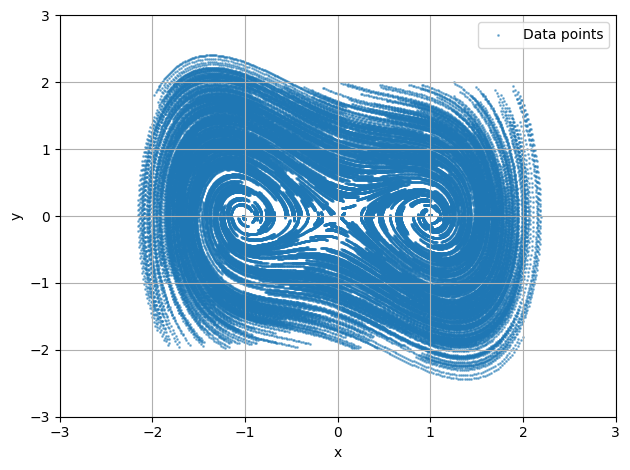

In [2]:
## Data Collection and Visualization
sys1 = systems(name = 'duffing_eqn')
n = sys1.n

traj_length = 100
N = 1000 * traj_length  # Total data points
#X1,Y1 = sys1.gather_data(num_samples= N, plot_results=False)
X2,Y2 = sys1.gather_traj_data(num_traj = N // traj_length, traj_length= traj_length, plot_results=False)
print(" Data gathered. ")

#X = np.vstack((X1,X2))
#Y = np.vstack((Y1,Y2))
X = X2
Y = Y2
print(" Total data points: ", X.shape[0])

X_data = X

plt.scatter(X[:,0], X[:,1], s=1, alpha=0.5, label='Data points')
plt.xlabel('x'); plt.ylabel('y')
plt.legend()
plt.xlim([-3, 3]); plt.ylim([-3, 3])
plt.tight_layout()
plt.grid()
plt.show()


In [3]:
## Pick centers for the RBFs: K-means vs random subsample of data points.

n_global_centers = 500
use_kmeans_centers = True   # Set False to use random centers instead of K-means
random_center_seed = 42

centers_global = select_rbf_centers(
    X,
    n_global_centers,
    use_kmeans=use_kmeans_centers,
    random_state=random_center_seed,
)


Center selection: K-means (500 centers)
Time to compute K-means solution = 20.844 seconds
centers shape: (500, 2)


In [36]:
## Vanilla EDMD and coarse basin approximation

d_poly = 1
poly = PolynomialBasis(n=sys1.n, d=d_poly)
#Phi = build_thin_plate_dictionary(sys1.n, centers_global, d_poly=d_poly)
Phi = RadialBasis(sys1.n, centers=centers_global, gamma=10.0)
Phi = CombinedDictionary(Phi, poly)
#Phi = poly
s = Phi.s
print(f'Number of Dictionary elements = {s}')

Phi_X = Phi.evaluate(X)
Phi_Y = Phi.evaluate(Y)

lambda_vals, lambda_vecs = compute_approximate_invariant_observables(Phi_X, Phi_Y, epsilon = 1e-5)

print(f"Dimension of the approximate invariant space = {len(lambda_vals)}")
print(lambda_vals)


Number of Dictionary elements = 503
Dimension of the approximate invariant space = 6
[-9.53718179e-18  2.15548920e-07  2.83240915e-06  3.37991635e-06
  4.21036550e-06  9.14233675e-06]


In [37]:
import matplotlib.pyplot as plt


K_global = fit_edmd_operator(Phi_X, Phi_Y)

# Indicator eigenfunction (mu approx 1)
w_global, v_global = sorted_koopman_eigenmodes(K_global)


X_grid, V_grid, grid_points = make_phase_space_grid(xlim=(-2, 2), ylim=(-2, 2), n=300)
Phi_grid = Phi.evaluate(grid_points)

Max principal angle = 0.020559498602354932
eigval at idx = 1 is (1.0005037670590022+0j)


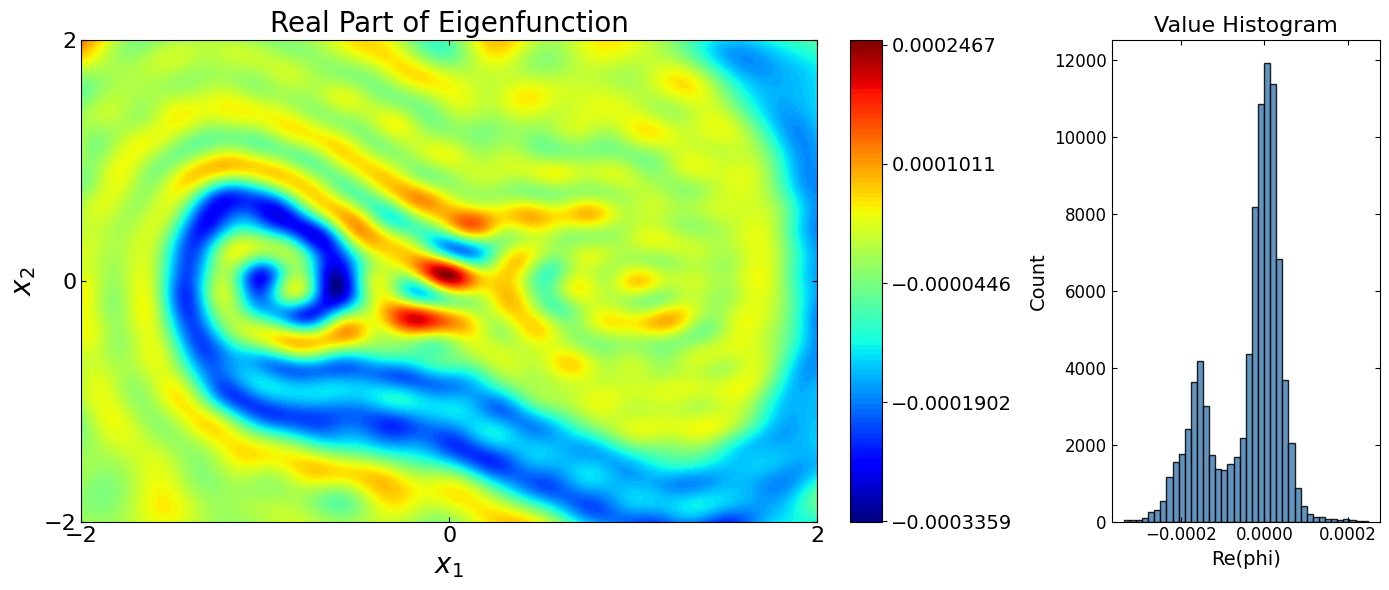

   > Separated data: 66717 points found in target basin.


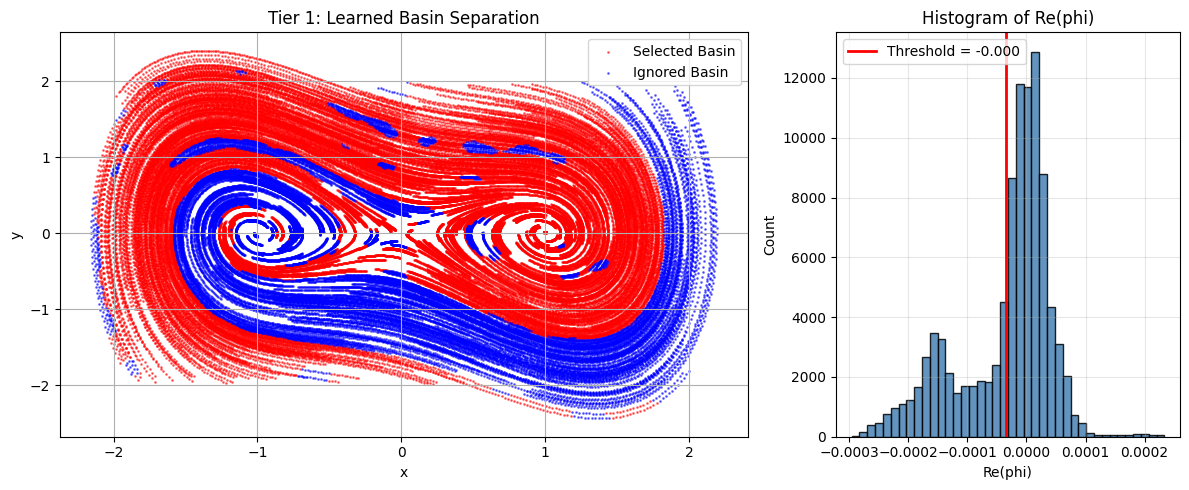

In [38]:
idx = 1
eig_val = w_global[idx]

IPT_eigf1 = max_principal_angle_eigenfunction(Phi_X, Phi_Y, v_global[:, idx])
print(f'Max principal angle = {IPT_eigf1}')
print(f"eigval at idx = {idx} is {eig_val}")

phi_values = apply_eigenvector(Phi_grid, v_global[:, idx])
_ = plot_eigenfunction_contour_histogram(X_grid, V_grid, phi_values)

phi_indicator = apply_eigenvector(Phi_X, v_global[:, idx])
epsilon_fix = 0.0
mask_basin, threshold, phi_real = basin_mask_from_eigenfunction(
    phi_indicator, epsilon_fix=epsilon_fix
)
X_basin, Y_basin = filter_snapshots_by_mask(X, Y, mask_basin)

print(f"   > Separated data: {X_basin.shape[0]} points found in target basin.")
_ = plot_basin_separation(X, mask_basin, phi_real, threshold)


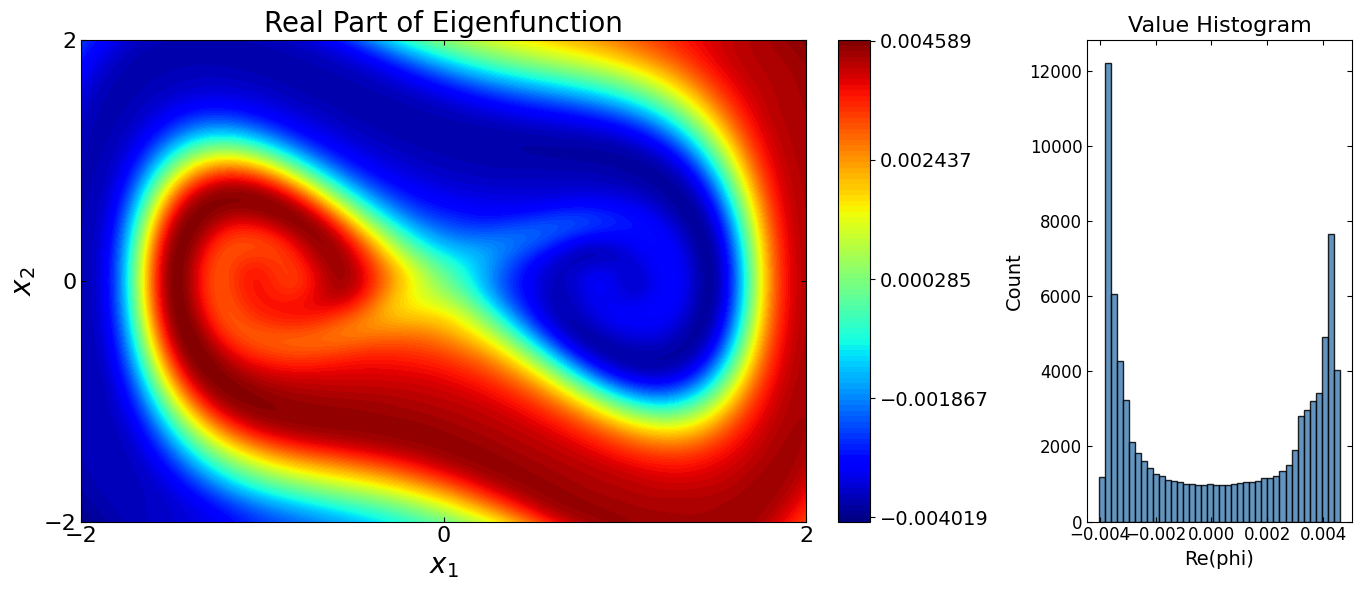

   > Separated data: 47568 points found in target basin.


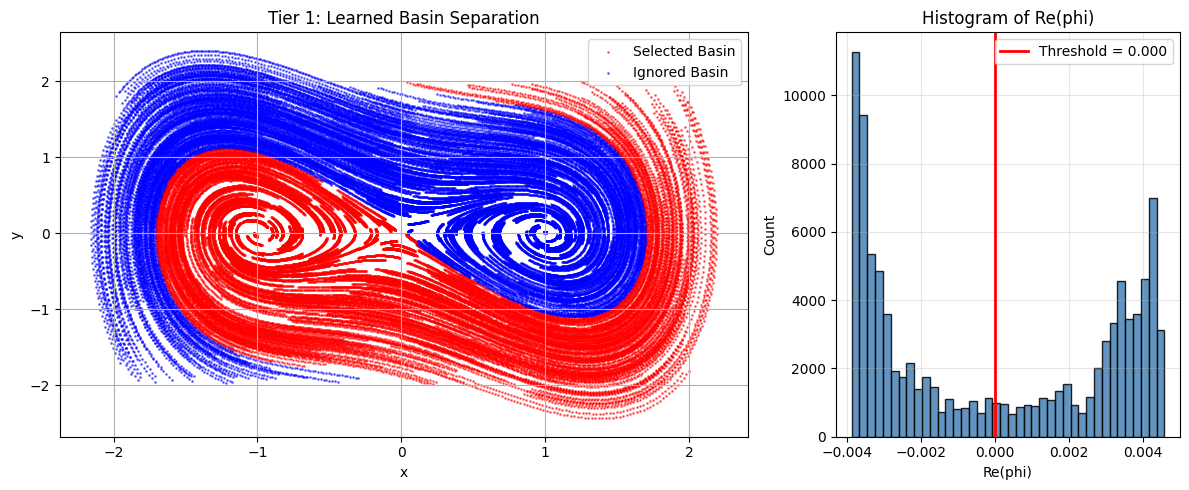

In [39]:
idx = 1
phi_values = apply_eigenvector(Phi_grid, lambda_vecs[:, idx])
_ = plot_eigenfunction_contour_histogram(X_grid, V_grid, phi_values)


phi_indicator = apply_eigenvector(Phi_X, lambda_vecs[:, idx])
epsilon_fix = 0.0
mask_basin, threshold, phi_real = basin_mask_from_eigenfunction(
    phi_indicator, epsilon_fix=epsilon_fix
)
X_basin, Y_basin = filter_snapshots_by_mask(X, Y, mask_basin)

print(f"   > Separated data: {X_basin.shape[0]} points found in target basin.")
_ = plot_basin_separation(X, mask_basin, phi_real, threshold)
